# Imports

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PODATKI = Path("../11_vaje/navodila")
if not PODATKI.exists():
    PODATKI = Path("../../11_vaje/navodila")
d2r = np.deg2rad

# Lokacija in Sonce (model z vaje 11)
phi, lam, S0 = 46.559, 15.639, 1361.0

# Plastenjak: dolga os v smeri sever-jug
a, b, h = 20.0, 5.0, 3.0                         # dolžina, širina, višina [m]
ploskve = {                                      # ime: (površina [m^2], naklon beta [°], azimut gama [°])
    "sever": (b * h, 90, 0), "vzhod": (a * h, 90, 90), "jug": (b * h, 90, 180),
    "zahod": (a * h, 90, 270), "streha": (a * b, 0, 0)}
S_ovoj = sum(p[0] for p in ploskve.values())      # površina ovoja
C = a * b * h * 1.2 * 1005 + a * b * 0.1 * 2.0e6  # toplotna kapaciteta: zrak + 10 cm tal [J/K]

# Funkcije

In [2]:
# --- Lega Sonca in obsevanje (vaja 11) ---
def deklinacija(n):
    return 23.44 * np.sin(2 * np.pi * (284 + n) / 365)


def casovna_enacba(n):
    B = 2 * np.pi * (n - 81) / 364
    return 9.87 * np.sin(2 * B) - 7.53 * np.cos(B) - 1.5 * np.sin(B)


def lega_sonca(n, t_utc):
    """Višina in azimut Sonca [°] za dan n in čas t_utc [h]."""
    d = deklinacija(n)
    H = 15 * (t_utc + lam / 15 + casovna_enacba(n) / 60 - 12)
    sa = np.sin(d2r(phi)) * np.sin(d2r(d)) + np.cos(d2r(phi)) * np.cos(d2r(d)) * np.cos(d2r(H))
    alt = np.rad2deg(np.arcsin(sa))
    c = (np.sin(d2r(d)) - sa * np.sin(d2r(phi))) / (np.cos(d2r(alt)) * np.cos(d2r(phi)))
    A = np.rad2deg(np.arccos(np.clip(c, -1, 1)))
    return alt, np.where(H > 0, 360 - A, A)


def direktno(alt, n):
    """Direktno obsevanje pravokotne ploskve v jasnem vremenu [W/m^2] (0 pod obzorjem)."""
    alt = np.asarray(alt, float)
    AM = 1 / (np.sin(d2r(np.maximum(alt, 0.01))) + 0.50572 * (np.maximum(alt, 0.01) + 6.07995)**(-1.6364))
    I_D = S0 * (1 + 0.033 * np.cos(2 * np.pi * n / 365)) * 0.7**(AM**0.678)
    return np.where(alt > 0, I_D, 0.0)


# --- Obsevanje ploskev ---
def cos_vpadni(alt, A, beta, gama):
    """Kosinus vpadnega kota žarkov na ploskev z naklonom beta in azimutom gama (negativno -> 0)."""
    c = (np.sin(d2r(alt)) * np.cos(d2r(beta))
         + np.cos(d2r(alt)) * np.sin(d2r(beta)) * np.cos(d2r(A - gama)))
    return np.where(alt > 0, np.maximum(c, 0), 0.0)


def obsevanje_ploskve(alt, A, n, beta, gama):
    """Obsevanje ploskve v jasnem vremenu [W/m^2]: direktno + razpršeno (10 % I_D sin(alt) (1 + cos beta)/2)."""
    I_D = direktno(alt, n)
    return I_D * cos_vpadni(alt, A, beta, gama) + 0.1 * I_D * np.sin(d2r(np.maximum(alt, 0))) * (1 + np.cos(d2r(beta))) / 2


# --- Toplotna bilanca ---
def korak_euler(T, T_zun, P_sonce, UA, dt):
    """En korak eksplicitne Eulerjeve metode za C dT/dt = P_sonce - UA (T - T_zun)."""
    return T + dt / C * (P_sonce - UA * (T - T_zun))


def korak_tocen(T, T_zun, P_sonce, UA, dt):
    """Točna rešitev za konstantna T_zun in P_sonce v koraku: relaksacija k T_ravn s tau = C/UA."""
    T_ravn = T_zun + P_sonce / UA
    return T_ravn + (T - T_ravn) * np.exp(-dt * UA / C)


def simulacija(vreme, U=6.0, tau_folija=0.8, T_min=None, T0=10.0, korak=korak_tocen):
    """Urna simulacija temperature v plastenjaku. Če je T_min podan, grelec ne dovoli T < T_min.
    Vrne (T [°C], moč gretja [W]) za vse ure."""
    UA = U * S_ovoj
    dt = 3600.0
    T = T0
    T_v, P_ogr = np.empty(len(vreme)), np.zeros(len(vreme))
    for k, (T_zun, P_s) in enumerate(zip(vreme["T"].to_numpy(), vreme["P_sonce"].to_numpy())):
        T = korak(T, T_zun, tau_folija * P_s, UA, dt)
        if T_min is not None and T < T_min:
            P_ogr[k] = C * (T_min - T) / dt
            T = T_min
        T_v[k] = T
    return T_v, P_ogr

# Testno območje

In [3]:
print(f"S_ovoj = {S_ovoj} m^2, C = {C/1e6:.2f} MJ/K, tau (U = 6) = {C / (6 * S_ovoj) / 3600:.2f} h")
# P1: poldne 21. 6.
alt, A = lega_sonca(172, 12 - lam / 15 - casovna_enacba(172) / 60)
print(f"21. 6. opoldne: alt = {float(alt):.2f}°, A = {float(A):.1f}°")
for ime, (S, beta, gama) in ploskve.items():
    print(f"  {ime:6s}: cos(theta) = {float(cos_vpadni(alt, A, beta, gama)):.3f}")

S_ovoj = 250.0 m^2, C = 20.36 MJ/K, tau (U = 6) = 3.77 h
21. 6. opoldne: alt = 66.88°, A = 180.0°
  sever : cos(theta) = 0.000
  vzhod : cos(theta) = 0.000
  jug   : cos(theta) = 0.393
  zahod : cos(theta) = 0.000
  streha: cos(theta) = 0.920


# Naloga 1 - Slika 2

21. 6. sever : E = 1.11 kWh/m^2
21. 6. vzhod : E = 3.63 kWh/m^2
21. 6. jug   : E = 2.33 kWh/m^2
21. 6. zahod : E = 3.63 kWh/m^2
21. 6. streha: E = 7.90 kWh/m^2
21. 12. sever : E = 0.05 kWh/m^2
21. 12. vzhod : E = 0.82 kWh/m^2
21. 12. jug   : E = 3.59 kWh/m^2
21. 12. zahod : E = 0.82 kWh/m^2
21. 12. streha: E = 1.19 kWh/m^2


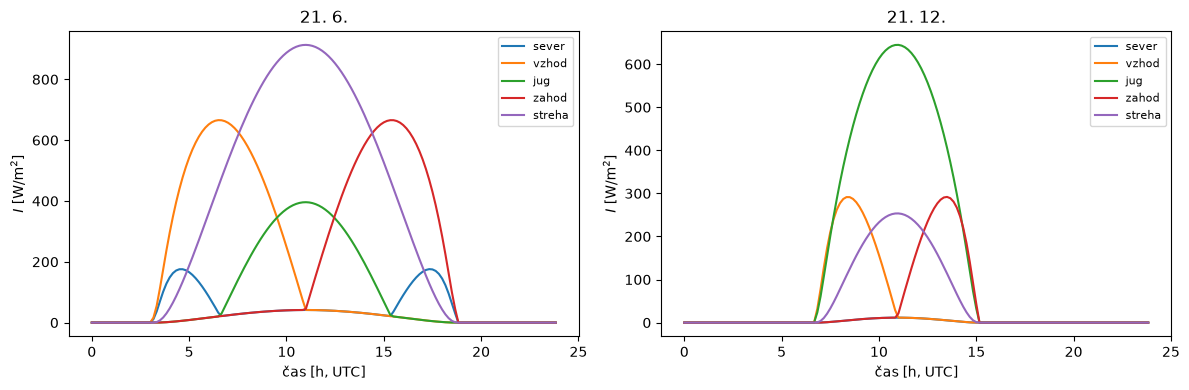

In [4]:
t = np.arange(0, 24, 1 / 6)
fig = plt.figure(figsize=(12, 4))
for k, (datum, n) in enumerate((("21. 6.", 172), ("21. 12.", 355))):
    alt, A = lega_sonca(n, t)
    ax = fig.add_subplot(1, 2, k + 1)
    for ime, (S, beta, gama) in ploskve.items():
        I = obsevanje_ploskve(alt, A, n, beta, gama)
        ax.plot(t, I, label=ime)
        print(f"{datum} {ime:6s}: E = {I.sum() / 6 / 1000:.2f} kWh/m^2")
    ax.set_title(datum)
    ax.set_xlabel("čas [h, UTC]")
    ax.set_ylabel("$I$ [W/m$^2$]")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

# Naloga 2

In [5]:
vreme = pd.read_csv(PODATKI / "Vreme_urni.csv")
cas = pd.to_datetime(vreme["date"] + " " + vreme["time"])
n_ura = cas.dt.dayofyear.to_numpy()
t_utc = cas.dt.hour.to_numpy() + 0.5 - 1          # sredina ure; čas v podatkih je CET (UTC+1)
alt_u, A_u = lega_sonca(n_ura, t_utc)
I_h = obsevanje_ploskve(alt_u, A_u, n_ura, 0, 0)
dnevi = pd.DataFrame({"n": n_ura, "J": vreme["J"], "I_h": I_h}).groupby("n").sum()
K = (dnevi["J"] / dnevi["I_h"]).clip(0, 1.2)
vreme["K"] = K.loc[n_ura].to_numpy()
P = np.zeros(len(vreme))
for ime, (S, beta, gama) in ploskve.items():
    P += S * obsevanje_ploskve(alt_u, A_u, n_ura, beta, gama)
vreme["P_sonce"] = vreme["K"] * P
mesec = cas.dt.month
tabela = pd.DataFrame({ime: [(S * obsevanje_ploskve(alt_u, A_u, n_ura, beta, gama) * vreme["K"])[mesec == m].sum() / 1000
                            for m in range(1, 13)] for ime, (S, beta, gama) in ploskve.items()}, index=range(1, 13))
print("Preglednica 2: mesečna energija na ploskve [kWh]")
print(tabela.round(0))
print("letno [MWh]:", (tabela.sum() / 1000).round(2).to_dict())

Preglednica 2: mesečna energija na ploskve [kWh]
    sever   vzhod     jug   zahod   streha
1    22.0  1307.0  1269.0  1302.0   3286.0
2    47.0  2520.0  1817.0  2504.0   6875.0
3    78.0  3826.0  1914.0  3836.0  11457.0
4   107.0  3796.0  1202.0  3787.0  12402.0
5   217.0  4053.0   836.0  4063.0  14194.0
6   395.0  5374.0   874.0  5367.0  19370.0
7   301.0  4794.0   873.0  4796.0  17087.0
8   170.0  4561.0  1210.0  4556.0  15284.0
9    88.0  4116.0  1721.0  4119.0  12816.0
10   48.0  2509.0  1660.0  2520.0   7103.0
11   25.0  1438.0  1308.0  1429.0   3678.0
12   18.0  1101.0  1185.0  1120.0   2674.0
letno [MWh]: {'sever': 1.52, 'vzhod': 39.4, 'jug': 15.87, 'zahod': 39.4, 'streha': 126.23}


# Naloga 3 - Slika 3

januar: T_zun -7.2 .. 4.3, T_not -5.2 .. 18.4 °C, <T_not - T_zun> = 3.3 K, max |Euler - točno| = 1.22 K
julij: T_zun 11.2 .. 33.4, T_not 14.7 .. 79.4 °C, <T_not - T_zun> = 20.6 K, max |Euler - točno| = 3.20 K


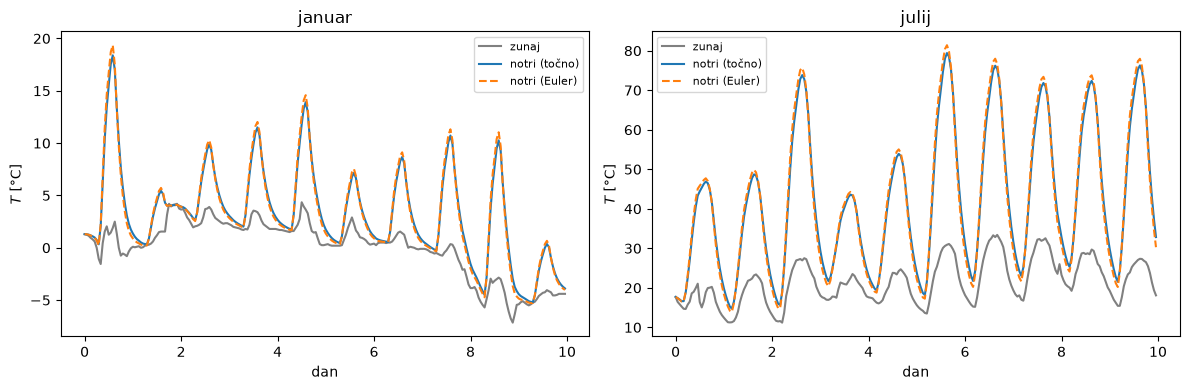

In [6]:
fig = plt.figure(figsize=(12, 4))
for k, (ime, zac) in enumerate((("januar", 0), ("julij", 181 * 24))):
    v = vreme.iloc[zac:zac + 240]
    T_t, _ = simulacija(v, T0=v["T"].iloc[0], korak=korak_tocen)
    T_e, _ = simulacija(v, T0=v["T"].iloc[0], korak=korak_euler)
    ax = fig.add_subplot(1, 2, k + 1)
    ax.plot(np.arange(240) / 24, v["T"], color="gray", label="zunaj")
    ax.plot(np.arange(240) / 24, T_t, label="notri (točno)")
    ax.plot(np.arange(240) / 24, T_e, "--", label="notri (Euler)")
    ax.set_title(ime)
    ax.set_xlabel("dan")
    ax.set_ylabel("$T$ [°C]")
    ax.legend(fontsize=8)
    print(f"{ime}: T_zun {v['T'].min():.1f} .. {v['T'].max():.1f}, T_not {T_t.min():.1f} .. {T_t.max():.1f} °C, "
          f"<T_not - T_zun> = {(T_t - v['T']).mean():.1f} K, max |Euler - točno| = {np.abs(T_e - T_t).max():.2f} K")
fig.tight_layout()
plt.show()

# Naloga 4 - Slika 4

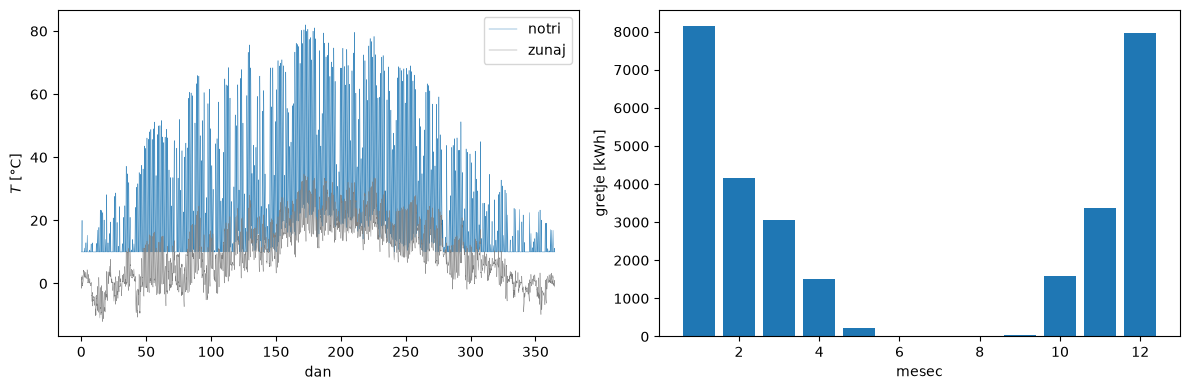

In [7]:
T_leto, P_leto = simulacija(vreme, U=6.0, tau_folija=0.8, T_min=10.0)
fig = plt.figure(figsize=(12, 4))
ax = fig.add_subplot(121)
ax.plot(np.arange(len(T_leto)) / 24, T_leto, lw=0.3, label="notri")
ax.plot(np.arange(len(T_leto)) / 24, vreme["T"], lw=0.3, color="gray", label="zunaj")
ax.set_xlabel("dan")
ax.set_ylabel("$T$ [°C]")
ax.legend()
ax = fig.add_subplot(122)
ax.bar(range(1, 13), [P_leto[mesec == m].sum() / 1000 for m in range(1, 13)])
ax.set_xlabel("mesec")
ax.set_ylabel("gretje [kWh]")
fig.tight_layout()
plt.show()

In [8]:
# Preglednica 4: letna energija za gretje (T_min = 10 °C)
for U in (6.0, 3.5):
    for tf in (0.7, 0.9):
        T_l, P_l = simulacija(vreme, U=U, tau_folija=tf, T_min=10.0)
        print(f"U = {U}, tau = {tf}: gretje = {P_l.sum() / 1e6:.2f} MWh, ur z gretjem = {(P_l > 0).sum()}, "
              f"ur nad 35 °C = {(T_l > 35).sum()}, T_max = {T_l.max():.1f} °C")

U = 6.0, tau = 0.7: gretje = 31.08 MWh, ur z gretjem = 2535, ur nad 35 °C = 1988, T_max = 75.6 °C
U = 6.0, tau = 0.9: gretje = 29.18 MWh, ur z gretjem = 2336, ur nad 35 °C = 2467, T_max = 88.4 °C
U = 3.5, tau = 0.7: gretje = 13.09 MWh, ur z gretjem = 1617, ur nad 35 °C = 3178, T_max = 96.1 °C
U = 3.5, tau = 0.9: gretje = 11.31 MWh, ur z gretjem = 1376, ur nad 35 °C = 3863, T_max = 115.1 °C
